# Feature engineering

**A model input is fair only if it was known when the forecast was made.**

Many forecasting leaks happen while the inputs are built: a column computed from the whole series, a scale fitted on data from after the forecast date, or the value being predicted left among the predictors. This chapter builds four helpers that make inputs from what was known at each row: past values as columns (`add_lagged_target`), cosine and sine features that put the end of a cycle next to its start (`cyclical_encoding`), a fixed set of calendar columns (`add_time_features`), and optional rolling summaries from the TSFEL library (`add_tsfel_features`).

We'll see a linear regression on three lag columns recover the weight that generated a mean-reverting series, December land next to January, and calendar columns come out the same whether they are built on a slice of the history, on all of it, or on the dates still to forecast.

**Development notebook.** The collapsed cells are the library code; expand one to edit it, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp features

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Four ways to describe the past

The DataFrame helpers return a new frame with the input columns first (for TSFEL, the ones you select), and they refuse to overwrite a column that already exists. None of the four fits anything to the data, so a training slice and a prediction slice get exactly the same treatment.

In [3]:
#| export features
from __future__ import annotations

from collections.abc import Sequence
from numpy.typing import ArrayLike, NDArray

import numpy as np
import pandas as pd
from timegym._internal import _real_array


In [4]:
#| export features
from timegym._internal import positive_int, nonnegative_int


### Past values as columns: `add_lagged_target`

Adds `y_t-1` to `y_t-k` for each column `y`: its value 1 to `k` rows earlier. The original column stays, as the target; leave it out of the inputs. `dropna=True`, the default, drops the first `k` rows, which have no full history; `False` keeps them with missing values.

In [5]:
#| export features
def add_lagged_target(
    df: pd.DataFrame, lags: int = 10, dropna: bool = True
) -> pd.DataFrame:
    """Append previous observations as {column}_t-{lag} in column-major order.

    The original columns remain unchanged; exclude the current target from a
    contemporaneous predictor matrix. Lags count rows, not calendar durations.
    dropna=True removes rows missing any original or generated value; False
    retains the original index and the missing warmup values. Zero lags adds
    no columns. The input is never mutated and name collisions raise.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    lags = nonnegative_int(lags, "lags")
    df = df.copy()
    for col in df.columns:
        for lag in range(1, 1 + lags):
            name = f"{col}_t-{lag}"
            if name in df.columns:
                raise ValueError(f"Lagged feature column already exists: {name}")
            df[name] = df[col].shift(lag)
    return df.dropna() if dropna else df


### Cycles as circles: `cyclical_encoding`

Turns a position in a cycle into a cosine and a sine, so the last position sits next to the first. The cycle is always given, never estimated from the data: `period=7, min_value=0` for weekdays numbered 0 to 6, `period=24` for hours, or `min_value=1, max_value=12` for months (the bounds are inclusive, so the period is 12). With `scaled=True` the values are already fractions of a cycle.

In [6]:
#| export features
def cyclical_encoding(
    values: ArrayLike,
    scaled: bool = False,
    min_value: float | None = None,
    max_value: float | None = None,
    *,
    period: float | None = None,
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    """Return cosine/sine features using a fixed cycle and phase origin.

    Prefer period=7, min_value=0 for weekdays and period=24 for hours.
    Explicit bounds denote inclusive discrete labels, so bounds 0..6
    imply period 7. The period is never estimated from the observed sample.
    With scaled=True, values already express fractions of a full cycle.
    """
    values = _real_array(values, "cyclical values")
    if not np.isfinite(values).all():
        raise ValueError("cyclical values must be finite")
    if scaled:
        if any(value is not None for value in (min_value, max_value, period)):
            raise ValueError("scaled values cannot also specify bounds or a period")
        phase = values
    else:
        origin = 0.0 if min_value is None else float(min_value)
        if period is not None and max_value is not None:
            raise ValueError("Specify period or inclusive max_value, not both")
        if period is None:
            if max_value is None:
                raise ValueError(
                    "Supply an explicit period or inclusive min_value/max_value bounds"
                )
            period = float(max_value) - origin + 1.0
        period = float(period)
        if not np.isfinite(origin) or not np.isfinite(period) or period <= 0:
            raise ValueError(
                "The cycle origin must be finite and period must be positive"
            )
        phase = (values - origin) / period
    return np.asarray(np.cos(phase * 2 * np.pi)), np.asarray(np.sin(phase * 2 * np.pi))


### A fixed set of calendar columns: `add_time_features`

Needs a DatetimeIndex and adds the same 20 columns whatever the dates: `time` (days since 1 January 1970), `year`, and a cosine and sine for the quarter, month, day of the month, weekday, hour, minute, second and microsecond, plus `day_adj`, the day as a fraction of its own month. Calendar fields use the index's local clock time.

In [7]:
#| export features
def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add a stable calendar-feature schema to a DatetimeIndex dataframe.

    Calendar fields use local clock time. 'time' is elapsed days since the
    Unix epoch (UTC for timezone-aware indexes), with no sample-fitted scaling.
    A fixed schema keeps separate training and prediction slices compatible.
    Preserve the input columns and index; reject generated-name collisions.
    No statistic is fitted on the sample and the input is never mutated.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise ValueError("add_time_features requires a DatetimeIndex without NaT")
    components_names = (
        "quarter",
        "month",
        "day",
        "weekday",
        "hour",
        "minute",
        "second",
        "microsecond",
        "day_adj",
    )
    generated = {"time", "year"} | {
        f"{name}_{part}" for name in components_names for part in ("cos", "sin")
    }
    collisions = [name for name in df.columns if name in generated]
    if collisions:
        raise ValueError(f"Calendar feature columns already exist: {collisions}")
    df = df.copy()
    index = df.index
    epoch = pd.Timestamp("1970-01-01", tz="UTC" if index.tz is not None else None)
    df["time"] = (index - epoch).total_seconds() / 86400.0
    df["year"] = index.year
    components = (
        ("quarter", index.quarter, 4, 1),
        ("month", index.month, 12, 1),
        ("day", index.day, 31, 1),
        ("weekday", index.day_of_week, 7, 0),
        ("hour", index.hour, 24, 0),
        ("minute", index.minute, 60, 0),
        ("second", index.second, 60, 0),
        ("microsecond", index.microsecond, 1_000_000, 0),
    )
    for name, values, period, origin in components:
        df[f"{name}_cos"], df[f"{name}_sin"] = cyclical_encoding(
            values, period=period, min_value=origin
        )
    fraction_of_month = (index.day - 1) / index.days_in_month
    df["day_adj_cos"], df["day_adj_sin"] = cyclical_encoding(
        fraction_of_month, scaled=True
    )
    return df


### Rolling summaries, optional: `add_tsfel_features`

Computes [TSFEL](https://tsfel.readthedocs.io)'s features (all of them, or one domain such as `domain='statistical'`) over a sliding window of `window_size` rows. Install `timegym[features]` first; TSFEL is imported only when this runs. At row `t` the window ends at row `t - lag`, so the default `lag=1` never includes the value being predicted, and `lag=0` does. `frequency` is the sampling rate in Hz that TSFEL's spectral features need. This notebook doesn't call it, because TSFEL is optional.

In [8]:
#| export features
def add_tsfel_features(
    df: pd.DataFrame,
    use_cols: str | Sequence[str] | None = None,
    window_size: int = 100,
    domain: str | None = None,
    frequency: float = 100,
    dropna: bool = True,
    show_progress: bool = False,
    lag: int = 1,
) -> pd.DataFrame:
    """Extract rolling features without importing TSFEL until it is requested.

    At output row t the last window observation is t-lag. Thus the default
    lag=1 excludes the current row; lag=0 includes it. Row counts define windows;
    frequency is the sampling frequency in Hz passed to TSFEL. Install
    timegym[features] to use this helper. Return selected original columns plus
    extracted columns at the original index, without mutating the input.
    dropna=True removes rows missing any selected or extracted value; False
    keeps warmup rows with missing features. Name collisions raise.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    window_size = positive_int(window_size, "window_size")
    lag = nonnegative_int(lag, "lag")
    if not np.isfinite(frequency) or frequency <= 0:
        raise ValueError("frequency must be positive and finite")
    first_row = window_size + lag - 1
    if len(df) <= first_row:
        raise ValueError("Insufficient rows for the requested window_size and lag")
    try:
        import tsfel
    except ImportError as exc:
        raise ImportError(
            "Install timegym[features] to use TSFEL feature extraction"
        ) from exc
    data = (
        df
        if use_cols is None
        else df[[use_cols] if isinstance(use_cols, str) else list(use_cols)]
    )
    if len(data.columns) == 0 or not data.columns.is_unique:
        raise ValueError("use_cols must select at least one column without duplicates")
    cfg = tsfel.get_features_by_domain(domain=domain)
    iterator = range(first_row, len(df))
    if show_progress:
        try:
            from tqdm import tqdm
        except ImportError as exc:
            raise ImportError(
                "Install timegym[features] to display TSFEL progress"
            ) from exc
        iterator = tqdm(iterator)
    features = []
    for row in iterator:
        window_end = row - lag + 1
        window = data.iloc[window_end - window_size : window_end]
        features.append(
            tsfel.time_series_features_extractor(cfg, window, verbose=0, fs=frequency)
        )
    features = pd.concat(features, ignore_index=True)
    if not features.columns.is_unique or any(
        name in data.columns for name in features.columns
    ):
        raise ValueError(
            "TSFEL feature columns must be unique and distinct from input columns"
        )
    features.index = df.index[first_row:]
    result = pd.concat([data, features], axis=1)
    return result.dropna() if dropna else result


## Past values as columns

The series is mean reversion (AR(1)): each step keeps 0.8 of the previous step's distance from the mean, plus a fresh shock. Three lag columns give a regression the previous three steps. If they are built right, it should put a weight near 0.8 on the most recent one and near zero on the two before.

In [9]:
from sklearn.linear_model import LinearRegression
from timegym import Scenario

series = Scenario('ar1', context_length=500, horizon=12,
                  parameters={'phi': 0.8, 'sigma': 1.0}).generate(seed=3).task.context
lagged = add_lagged_target(series, lags=3)
np.testing.assert_array_equal(lagged['y_t-1'].iloc[1:], lagged['y'].iloc[:-1])  # each value reappears one row later
display(lagged.head(4).round(2))

inputs, target = lagged.drop(columns='y'), lagged['y']  # never the value being predicted
weights = pd.Series(LinearRegression().fit(inputs, target).coef_, index=inputs.columns)
assert abs(weights['y_t-1'] - 0.8) < 0.05 and weights[['y_t-2', 'y_t-3']].abs().max() < 0.1  # the last step carries the weight
print('Weights learned: ' + ', '.join(f'{name} {weight:.2f}' for name, weight in weights.items()))

,y,y_t-1,y_t-2,y_t-3
3,-0.13,0.55,0.17,3.40
4,-0.55,-0.13,0.55,0.17
5,-0.66,-0.55,-0.13,0.55
6,-2.55,-0.66,-0.55,-0.13


Weights learned: y_t-1 0.78, y_t-2 0.03, y_t-3 -0.00


Read the table along a diagonal: the value of `y` at step 3 (-0.13) reappears as `y_t-1` at step 4 and as `y_t-2` at step 5. Steps 0 to 2 are gone because they have no full history. The regression puts 0.78 on the last step and almost nothing on the two before (0.03 and -0.00): the lag columns hold exactly the information the process uses, and nothing from the row being predicted.

## December next to January

Month numbers put December (12) eleven apart from January (1), though they are neighbors in the calendar. On a circle they are neighbors too.

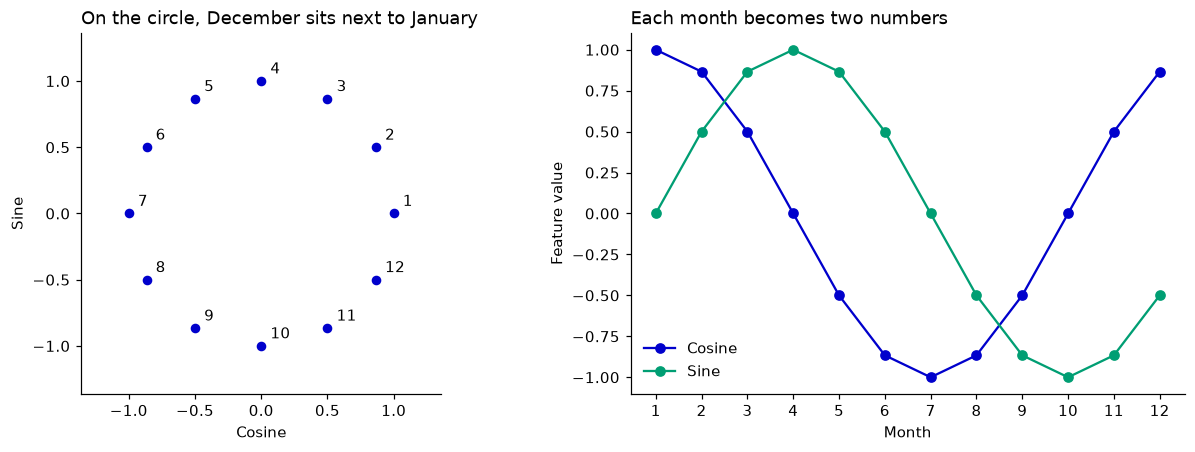

,Apart as month numbers,Apart on the circle
December and January,11,0.52
January and February,1,0.52
January and July,6,2.00


In [10]:
months = np.arange(1, 13)
cosine, sine = cyclical_encoding(months, period=12, min_value=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].scatter(cosine, sine, color='#0000CC', s=28)
for month, x, y in zip(months, cosine, sine):
    axes[0].annotate(str(month), (x, y), xytext=(6, 5), textcoords='offset points')
axes[0].set(xlabel='Cosine', ylabel='Sine', title='On the circle, December sits next to January', aspect='equal')
axes[0].margins(.18)
axes[1].plot(months, cosine, color='#0000CC', marker='o', label='Cosine')
axes[1].plot(months, sine, color='#009E73', marker='o', label='Sine')
axes[1].set(xlabel='Month', ylabel='Feature value', xticks=months, title='Each month becomes two numbers')
axes[1].legend()
plt.show()


def apart(a, b):
    # Straight-line distance between two months on the circle.
    return float(np.hypot(cosine[a - 1] - cosine[b - 1], sine[a - 1] - sine[b - 1]))


pairs = {'December and January': (12, 1), 'January and February': (1, 2), 'January and July': (1, 7)}
distances = pd.DataFrame({'Apart as month numbers': [abs(a - b) for a, b in pairs.values()],
                          'Apart on the circle': [apart(a, b) for a, b in pairs.values()]}, index=list(pairs))
assert np.isclose(apart(12, 1), apart(1, 2))  # December is as close to January as February is
np.testing.assert_allclose(cyclical_encoding([1, 12], period=12, min_value=1)[0], cosine[[0, 11]])  # two months alone get the same numbers
distances.round(2)

On the circle December and January are 0.52 apart, the same as January and February, and July sits opposite January at 2.00, as far apart as two points on the circle can be. Encoding January and December alone gives the same numbers as encoding all twelve months, because the period is given rather than learned from the data: a training slice that happens to hold only some months is encoded like everything else. Each number alone would be ambiguous: February and December share a cosine (0.87), and only the sine tells them apart.

## Calendar columns, for the history and for the dates to forecast

Lag columns stop at the forecast date: to forecast two steps ahead, the value one step ahead isn't known yet. The calendar is known in advance. Here the history is two months of daily dates ending on 31 December 2023, and we build the calendar columns for the history, for a slice of it, and for the week to forecast.

In [11]:
freq = 'D'  # daily
history = pd.DataFrame({'y': 0.0}, index=pd.date_range('2023-11-01', '2023-12-31', freq=freq))  # only the dates matter here
dates_to_forecast = pd.date_range(history.index[-1], periods=8, freq=freq)[1:]  # the next 7 dates
calendar = add_time_features(history)
future_calendar = add_time_features(pd.DataFrame(index=dates_to_forecast))  # dates only, no values

pd.testing.assert_frame_equal(add_time_features(history.iloc[:20]), calendar.iloc[:20])  # a slice gets the same numbers
assert list(future_calendar.columns) == list(calendar.columns.drop('y'))  # the same 20 columns for the dates to forecast
both = pd.concat([calendar.drop(columns='y'), future_calendar])
constant = [name for name in both.columns if both[name].nunique() == 1]
print(f'{both.shape[1]} calendar columns. Constant on these dates: {", ".join(constant)}.')
shown = ['time', 'year', 'month_cos', 'month_sin', 'weekday_cos', 'weekday_sin']
pd.concat({'History': calendar[shown].iloc[-2:], 'To forecast': future_calendar[shown].iloc[:2]}).round(3)

20 calendar columns. Constant on these dates: hour_cos, hour_sin, minute_cos, minute_sin, second_cos, second_sin, microsecond_cos, microsecond_sin.


time  year  month_cos  month_sin  weekday_cos  \
History     2023-12-30  19721.0  2023      0.866       -0.5       -0.223   
            2023-12-31  19722.0  2023      0.866       -0.5        0.623   
To forecast 2024-01-01  19723.0  2024      1.000        0.0        1.000   
            2024-01-02  19724.0  2024      1.000        0.0        0.623   

                        weekday_sin  
History     2023-12-30       -0.975  
            2023-12-31       -0.782  
To forecast 2024-01-01        0.000  
            2024-01-02        0.782

The dates to forecast get the same 20 columns as the history, built from the dates alone, and the first 20 days come out identical whether built alone or with the rest. From 31 December to 1 January `time` counts on by one day, `year` steps up, and the month moves one twelfth of the way around its circle, back to January's point. On daily dates the eight hour, minute, second and microsecond columns are constant (cosine 1, sine 0); the set of columns is fixed so that every slice matches, so drop the constant ones if your model minds.

## Change one thing

- Leave `y` among the inputs (`inputs = lagged`). The fit becomes perfect, with all the weight on `y` itself and none on the last step, and the assert fails. That is what a leak looks like.
- Give the regression 10 lags instead of 3: do the weights on the older steps stay near zero?
- Use hourly dates, `freq = 'h'`: which calendar columns stop being constant?

**What this doesn't cover.** Lags count rows, not calendar time: on irregular timestamps `y_t-1` is the previous row, however long ago it was. The helpers build inputs; choosing which ones to give a model, and keeping the target out of them, is still up to you. The regression forecasters in [06 · Forecasting models](06_forecasting_models.ipynb) cut their own windows of past values, so you need `add_lagged_target` only when you assemble inputs yourself.

**Next:** [05 · Target engineering](05_target_engineering.ipynb): the values a model learns to predict, and transforms it can undo, as used in [Target transforms](29_target_transforms.ipynb).